# Worth 188 EUR? Public reaction to the SKIMS 2026 Accessories Advent Calendar

**Question:** SKIMS launched a 12-day, 188 euro-worth accessories advent calendar on 29 October 2026. Online it was widely mocked.
Is the backlash mainly about **price**, the **contents**, the **lack of actual SKIMS clothing**, or the **brand/Kardashians** themselves?

**Data:** Top-level YouTube comments on unboxing and review videos published after launch (collected with `collect_comments.py`).

**Method:**
1. Clean and filter comments
2. Score sentiment with VADER (a rule-based model built for social media text)
3. Validate VADER against 100 comments I labelled by hand
4. Tag comments into complaint themes with keyword rules

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

DATA = Path("data")
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)

# Chart style: one hue, quiet axes, so the data is what stands out
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#898781"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "font.size": 11, "figure.dpi": 120,
})

## 1. Load and clean

In [2]:
raw = pd.read_csv(DATA / "comments_raw.csv", parse_dates=["published_at"])
print(f"Raw comments: {len(raw):,} from {raw.video_id.nunique()} videos")

df = raw.copy()
df["text"] = df["text"].astype(str).str.strip()
df = df.drop_duplicates(subset="comment_id")
df = df.drop_duplicates(subset="text")                 # copy-paste spam
df = df[df["text"].str.len() >= 3]                     # drop empty / single emoji

# Keep comments that are mostly Latin script (rough English filter)
latin_share = df["text"].apply(lambda t: sum(c.isascii() for c in t) / len(t))
df = df[latin_share > 0.7].reset_index(drop=True)

print(f"After cleaning: {len(df):,} comments ({len(raw) - len(df):,} removed)")
df[["video_title", "text", "likes"]].sample(5, random_state=1)

Raw comments: 1,135 from 10 videos
After cleaning: 1,106 comments (29 removed)


,video_title,text,likes
304,The $300 Skims Advent Calendar Is A SCAM...,Random things I have in my bag is now an adven...,0
1070,The Dollar Store Hair Scrunchies are frying me...,SCAM 😬,0
126,The $300 Skims Advent Calendar Is A SCAM...,"I thought advent calendars had 24/25 ""windows""...",1
975,The Dollar Store Hair Scrunchies are frying me...,This is sad! They fly around on private jets ...,0
236,The $300 Skims Advent Calendar Is A SCAM...,it seems all these luxury brand advent calenda...,0


In [3]:
# Which videos does the data come from? (check one channel isn't dominating)
(df.groupby(["channel", "video_title"]).size()
   .sort_values(ascending=False).rename("comments").to_frame().head(15))

comments
channel               video_title                                                 
Haylo Hayley          The $300 Skims Advent Calendar Is A SCAM...              497
Bo Grant              The Dollar Store Hair Scrunchies are frying me ...       355
                      $150 for $10 worth of kids keychains is diaboli...        63
Henna Ali             Skims Accessories Advent Calendar 👀                       60
Reyah the Last Dragon Why SKIMS’ $148 Advent Calendar Is Facing Backlash        49
Myah Rodriguez        SKIMS Advent Calendar 2026⁉️ #skims #skit #parody         33
Please date cds       SKIMS ADVENT CALENDAR #skims #adventcalendarope...        13
Detective Collective  Skims Advent Calendar 2026 | What’s inside?               13
jesse tierney         I got my girlfriend the SKIMS ADVENT CALENDER! ...        13
Miya Mocha            This CRAZY New SKIMS Advent Calendar is a Mess            10

## 2. Sentiment with VADER
VADER gives each comment a `compound` score from -1 (very negative) to +1 (very positive).
The standard cut-offs are: >= 0.05 positive, <= -0.05 negative, otherwise neutral.

In [4]:
vader = SentimentIntensityAnalyzer()
df["vader_compound"] = df["text"].apply(lambda t: vader.polarity_scores(t)["compound"])

def to_label(score):
    if score >= 0.05: return "positive"
    if score <= -0.05: return "negative"
    return "neutral"

df["vader_label"] = df["vader_compound"].apply(to_label)
df["vader_label"].value_counts(normalize=True).round(3).to_frame("share")

,share
vader_label,
positive,0.411
negative,0.358
neutral,0.231


## 3. Does VADER actually work on this data?
Social media comments are full of sarcasm ("love paying £158 for hair ties 😍"), which rule-based models misread.
So before trusting the numbers, I hand-labelled a random sample of 100 comments and measured agreement.



In [5]:
label_file = DATA / "labels.csv"
if not label_file.exists():
    sample = df.sample(min(100, len(df)), random_state=42)[["comment_id", "text"]].copy()
    sample["my_label"] = ""
    sample.to_csv(DATA / "labels_to_fill.csv", index=False)
    print("Created data/labels_to_fill.csv - fill in my_label, save as data/labels.csv, then re-run.")

In [6]:
if label_file.exists():
    labels = pd.read_csv(label_file, encoding="utf-8-sig", sep=None, engine="python")
    labels.columns = [str(c).strip().lower() for c in labels.columns]
    print("Columns found in labels.csv:", list(labels.columns))

    # Use column position in case Excel renamed them: 1st = comment_id, last = my_label
    labels = labels.rename(columns={labels.columns[0]: "comment_id", labels.columns[-1]: "my_label"})
    labels = labels[labels["my_label"].astype(str).str.strip().str.lower() != "my_label"]  # drop repeated header row
    labels = labels.dropna(subset=["my_label"])
    labels["my_label"] = labels["my_label"].astype(str).str.strip().str.lower()

    # Take the comment text from the original data (avoids Excel emoji mangling)
    check = labels[["comment_id", "my_label"]].merge(
        df[["comment_id", "vader_label", "text"]], on="comment_id")

    accuracy = (check["my_label"] == check["vader_label"]).mean()
    print(f"VADER agrees with my labels on {accuracy:.0%} of {len(check)} comments")

    order = ["negative", "neutral", "positive"]
    confusion = pd.crosstab(check["my_label"], check["vader_label"],
                            rownames=["My label"], colnames=["VADER"]).reindex(index=order, columns=order, fill_value=0)
    display(confusion)

    wrong = check[check["my_label"] != check["vader_label"]]
    print("\nExamples VADER got wrong:")
    for _, r in wrong.head(8).iterrows():
        print(f"  me={r.my_label:<8} vader={r.vader_label:<8} | {r.text[:110]}")
else:
    print("No labels.csv yet - skip for now and come back to it.")
    

Columns found in labels.csv: ['column1', 'column2', 'column3']
VADER agrees with my labels on 39% of 100 comments


VADER,negative,neutral,positive
My label,,,
negative,31,19,27
neutral,5,4,8
positive,2,0,4



Examples VADER got wrong:
  me=negative vader=positive | My question is, why would anyone want to buy a skims calendar, at all? When there are so many fun ones out the
  me=negative vader=positive | That's honestly, really boring as an advent calendar, and personally if I had to make an advent calendar, it w
  me=neutral  vader=positive | a pair of underwear could fit in there
  me=negative vader=neutral  | Anyone who wants an Advent calendar after the age of 8 ANYWAY should have their head examined.
  me=negative vader=positive | But guys, the joy of surprise is priceless 😂😂😂
  me=negative vader=positive | This is how I felt everytime a new episode of Stranger Things finale came out 😅
  me=negative vader=neutral  | 100% filled with items they couldn't sell!
  me=negative vader=neutral  | Another day another scam from rich people.


In [7]:
labels["my_label"].value_counts(normalize=True).round(3)


my_label
negative    0.77
neutral     0.17
positive    0.06
Name: proportion, dtype: float64

## 4. What are people complaining about? Theme tagging
Each comment is tagged with any themes whose keywords it contains (a comment can have several, or none).
The keyword lists are deliberately simple and readable. 

In [8]:
THEMES = {
    "Price / value":       r"\bprice|£|\$|\beuro|€|expensive|overpriced|worth|value|money|robbery|scam|rip ?off|\bcost|afford|pay(ing)?\b",
    "Contents":            r"hair ?ties?|scrunchie|keychain|key chain|bobby ?pins?|clips?\b|headband|squishy|mirror|elastic",
    "No actual clothing":  r"underwear|pant(y|ies)|clothes|clothing|\bbras?\b|shapewear|lounge|actual skims|real skims",
    "Quality / cheapness": r"cheap(ly)?|quality|flimsy|plastic|temu|shein|aliexpress|dollar (store|tree)|penneys|primark|poundland|dupe",
    "Kardashian / brand":  r"\bkim\b|kardashian|kylie|kendall|khlo[eé]|kourtney|kris|celebrit|billionaire|greed",
}

for theme, pattern in THEMES.items():
    df[theme] = df["text"].str.contains(pattern, flags=re.IGNORECASE, regex=True)

theme_cols = list(THEMES)
df["any_theme"] = df[theme_cols].any(axis=1)
print(f"{df['any_theme'].mean():.0%} of comments match at least one theme")

summary = pd.DataFrame({
    "comments": [df[t].sum() for t in theme_cols],
    "share_of_all": [df[t].mean() for t in theme_cols],
    "avg_sentiment": [df.loc[df[t], "vader_compound"].mean() for t in theme_cols],
    "share_negative": [(df.loc[df[t], "vader_label"] == "negative").mean() for t in theme_cols],
    "avg_likes": [df.loc[df[t], "likes"].mean() for t in theme_cols],
}, index=theme_cols).sort_values("share_of_all", ascending=False)
summary.style.format({"share_of_all": "{:.0%}", "avg_sentiment": "{:+.2f}",
                      "share_negative": "{:.0%}", "avg_likes": "{:.1f}"})

C:\Users\ohugh\AppData\Local\Temp\ipykernel_24860\3775975777.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df[theme] = df["text"].str.contains(pattern, flags=re.IGNORECASE, regex=True)


54% of comments match at least one theme


,comments,share_of_all,avg_sentiment,share_negative,avg_likes
Price / value,401,36%,-0.03,45%,24.4
Kardashian / brand,130,12%,+0.02,37%,40.3
Quality / cheapness,94,8%,+0.02,39%,22.9
No actual clothing,81,7%,+0.05,37%,7.2
Contents,76,7%,+0.13,33%,22.6


In [9]:
# Sanity check: read a few comments from each theme
for t in theme_cols:
    print(f"\n=== {t} ===")
    for txt in df.loc[df[t], "text"].sample(min(3, df[t].sum()), random_state=0):
        print("  -", txt[:120])


=== Price / value ===
  - Skims scam.
  - Historically, retail has a profit margin of 90% when it hits the shelves, so that tracks.  (Damaged, lost, or stolen ite
  - The most I have ever spent on an advent calendar was, like... $30, and that was one with multiple plush toys and clothin

=== Contents ===
  - Im sorry but Hair ties,squishies and ornaments are not accessories
  - How are you not more mad about this?? You literally spent $150 bucks on hair ties, Bobby pins and lame ass Keychain all 
  - I haven't seen any advent calendar in years that is not, to some degree, a rip off. And I love to watch the unboxings ev

=== No actual clothing ===
  - Those aren't 'bra straps' they are headbands often used by ballet dancers. Dirt cheap though and originally they did jus
  - 2:24 those are replacement bra straps
  - The bra straps are headbands.  Bra strap head bands were a thing in the 90s

=== Quality / cheapness ===
  - If I paid $276 and got hair ties, cheap hairpins and a bra strap

### Chart 1: What the conversation is about

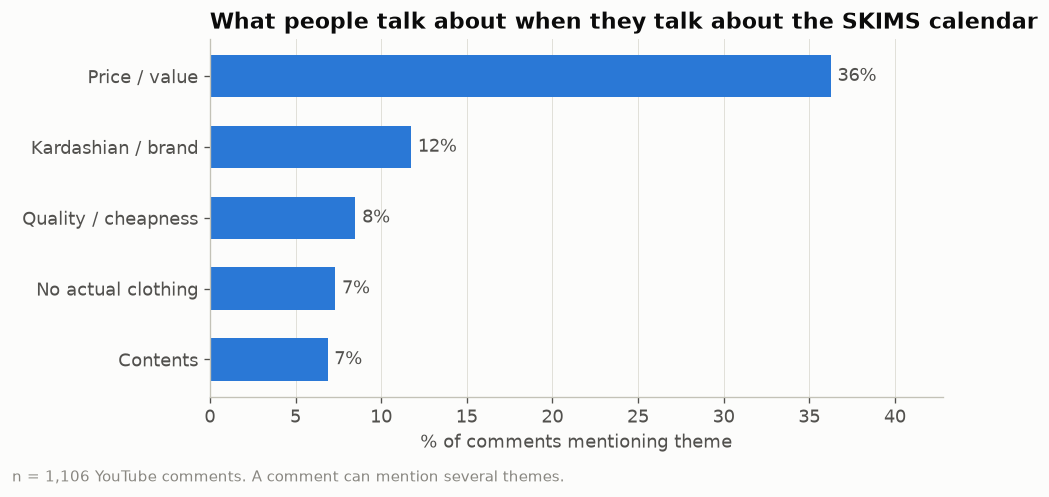

In [10]:
s = summary.sort_values("share_of_all")
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(s.index, s["share_of_all"] * 100, color=BLUE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in s["share_of_all"]], padding=4, color=INK2)
ax.set_xlabel("% of comments mentioning theme")
ax.set_title("What people talk about when they talk about the SKIMS calendar")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, s["share_of_all"].max() * 100 * 1.18)
fig.text(0.01, -0.02, f"n = {len(df):,} YouTube comments. A comment can mention several themes.",
         color=GREY, fontsize=9)
fig.tight_layout()
fig.savefig(FIGS / "1_theme_share.png", bbox_inches="tight")
plt.show()

### Chart 2: Which themes are the most negative?

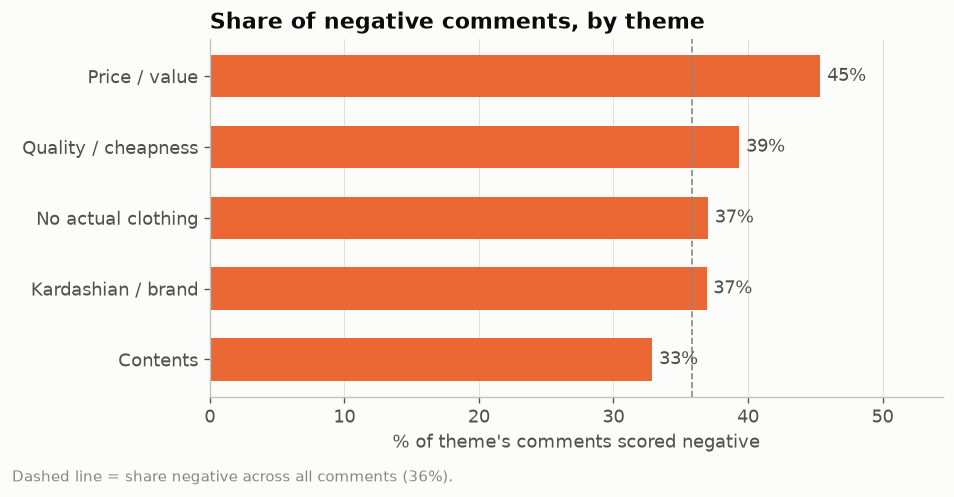

In [11]:
s = summary.sort_values("share_negative")
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(s.index, s["share_negative"] * 100, color=ORANGE, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in s["share_negative"]], padding=4, color=INK2)
overall_neg = (df["vader_label"] == "negative").mean() * 100
ax.axvline(overall_neg, color=GREY, linestyle="--", linewidth=1)
fig.text(0.01, -0.02, f"Dashed line = share negative across all comments ({overall_neg:.0f}%).", color=GREY, fontsize=9)
ax.set_xlabel("% of theme's comments scored negative")
ax.set_title("Share of negative comments, by theme")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(s["share_negative"].max() * 100, overall_neg) * 1.2)
fig.tight_layout()
fig.savefig(FIGS / "2_negative_by_theme.png", bbox_inches="tight")
plt.show()

## 5. The value maths

,day,item,generic_price_eur,price_source_notes
0,1,Bear keychain,5.98,Amazon
1,2,3-pack hair elastic,1.99,Boots
2,3,3-pack satin scrunchie,5.49,Boots
3,4,3-pack bobby pin,2.44,Amazon
4,5,SKIMS squishy,8.99,Art & Hobby
5,6,2-pack clips,3.49,Boots
6,7,2-pack bra elastic headband,13.00,Sports Direct
7,8,3-pack bobby pin (pink),2.44,Boots
8,9,Comb keychain,7.31,Amazon
9,10,Logo keychain,9.86,Amazon


Calendar price:              €188.00
Same items on the high street: €89.43
The calendar costs 2.1x the high-street equivalent


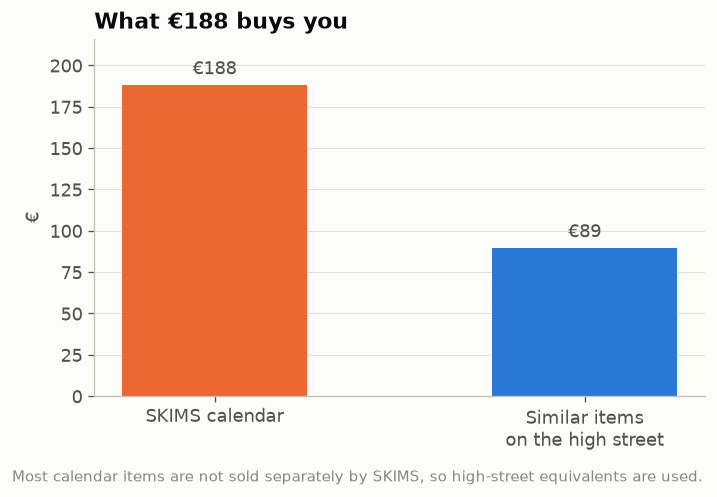

In [12]:
items = pd.read_csv(DATA / "calendar_items.csv")
CALENDAR_PRICE = 188  # <-- the € price from skims.com/en-ie

if items["generic_price_eur"].notna().all():
    high_street = items["generic_price_eur"].sum()
    display(items)
    print(f"Calendar price:              €{CALENDAR_PRICE:,.2f}")
    print(f"Same items on the high street: €{high_street:,.2f}")
    print(f"The calendar costs {CALENDAR_PRICE / high_street:.1f}x the high-street equivalent")

    totals = pd.Series({"SKIMS calendar": CALENDAR_PRICE,
                        "Similar items\non the high street": high_street})
    fig, ax = plt.subplots(figsize=(6, 4))
    bars = ax.bar(totals.index, totals.values, color=[ORANGE, BLUE], width=0.5)
    ax.bar_label(bars, labels=[f"€{v:,.0f}" for v in totals.values], padding=4, color=INK2)
    ax.set_ylabel("€")
    ax.set_title(f"What €{CALENDAR_PRICE:,.0f} buys you")
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, totals.max() * 1.15)
    fig.text(0.01, -0.02, "Most calendar items are not sold separately by SKIMS, so high-street equivalents are used.",
             color=GREY, fontsize=9)
    fig.tight_layout()
    fig.savefig(FIGS / "4_value_gap.png", bbox_inches="tight")
    plt.show()
else:
    print("Fill in generic_price_eur for every item first.")

## 6. Findings
Compared with general items, SKIMS advent calendar costs 2.1x more. SKIMS also fails to display what several items in their advent calendar, such as bobby pins and hair clips, retails for on their website, potentially misleading consumers on what their advent calendar is actually worth.
According to the data pull from one social media platform, YouTube, VADER classified a sample size of 100 comments with a share of 41% positive, 36% negative, and 23% neutral. However VADER, being a rules-based platform, finds it difficult to differentiate between sarcastic and genuine comments, so I took the sample size and classified each comment as either positive, negative, or neutral.
I found that 77% of these comments were negative, 17% were neutral, and 6% were positive. The model was fooled by sarcasm, so a brand relying on open source sentiment analysis tools would gravely underestimate the backlash of the campaign.
Over 45% of the comments focused on the price/value of the calendar, reflecting the importance of understanding the target dempographic and how prices should consider the current state of the economy and how consumer spending has changed.

## 7. What I'd tell SKIMS' marketing team
The advent calendat should have included at least one item of clothing, as SKIMS is primarily associated as an underwear brand. The calendar should also have only included items that SKIMS already sell so that consumers can identify the true worth of the calendar.

## 8. Limitations
- YouTube commenters are not a representative sample of SKIMS customers.
- Keyword themes miss comments that use other words for the same idea.
- VADER is rule-based and weak on sarcasm (see section 3).